### Import functions

In [77]:
base_path = "/home/olivia/Propagation/Datasets/"
fig_base_path = "/home/olivia/Propagation/Figures/Paper_Final_JPG/"


In [78]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib as mpl
import scipy.stats as stats

#plt.style.use('default')
mpl.rcParams["font.size"] = 12

In [79]:
""" sh = xr.open_dataset(base_path + "ERA5/ERA5_X_section_specific_humidity.nc").sel(latitude=slice(-5, -20)).mean(dim = 'latitude').rename({'longitude': 'x', 'valid_time': 'time'}).to_netcdf(base_path + "ERA5/ERA5_X_section_mean_specific_humidity_5_20.nc")
u_wind = xr.open_dataset(base_path + "ERA5/ERA5_X_section_u_component_of_wind.nc").sel(latitude=slice(-5, -20)).mean(dim = 'latitude').rename({'longitude': 'x', 'valid_time': 'time'}).to_netcdf(base_path + "ERA5/ERA5_X_section_mean_u_wind_5_20.nc")
w_wind = xr.open_dataset(base_path + "ERA5/ERA5_X_section_vertical_velocity.nc").sel(latitude=slice(-5, -20)).mean(dim = 'latitude').rename({'longitude': 'x', 'valid_time': 'time'}).to_netcdf(base_path + "ERA5/ERA5_X_section_mean_w_wind_5_20.nc")
sp = xr.open_dataset(base_path + "ERA5/ERA5_X_section_surface_pressure.nc").sel(latitude=slice(-5, -20)).mean(dim = ['latitude', 'valid_time']).rename({'longitude': 'x'}).to_netcdf(base_path + "ERA5/ERA5_X_section_mean_surface_pressure_5_20.nc") """

' sh = xr.open_dataset(base_path + "ERA5/ERA5_X_section_specific_humidity.nc").sel(latitude=slice(-5, -20)).mean(dim = \'latitude\').rename({\'longitude\': \'x\', \'valid_time\': \'time\'}).to_netcdf(base_path + "ERA5/ERA5_X_section_mean_specific_humidity_5_20.nc")\nu_wind = xr.open_dataset(base_path + "ERA5/ERA5_X_section_u_component_of_wind.nc").sel(latitude=slice(-5, -20)).mean(dim = \'latitude\').rename({\'longitude\': \'x\', \'valid_time\': \'time\'}).to_netcdf(base_path + "ERA5/ERA5_X_section_mean_u_wind_5_20.nc")\nw_wind = xr.open_dataset(base_path + "ERA5/ERA5_X_section_vertical_velocity.nc").sel(latitude=slice(-5, -20)).mean(dim = \'latitude\').rename({\'longitude\': \'x\', \'valid_time\': \'time\'}).to_netcdf(base_path + "ERA5/ERA5_X_section_mean_w_wind_5_20.nc")\nsp = xr.open_dataset(base_path + "ERA5/ERA5_X_section_surface_pressure.nc").sel(latitude=slice(-5, -20)).mean(dim = [\'latitude\', \'valid_time\']).rename({\'longitude\': \'x\'}).to_netcdf(base_path + "ERA5/ERA5_X_s

### Import data


In [80]:
# import driver data for composites (i.e. PDO, TNA, TSA, Nino3, Nino4, Nino34, Nino12)
driver_comp = pd.read_csv(base_path + "Data_for_x_sections/driver_composites.csv", index_col = 0, parse_dates = True)

# import drought indices (i.e. SPEI, SMAI, VHI, SSFI)
drought_comp = pd.read_csv(base_path + "Data_for_x_sections/drought_indices_vilcanota.csv", index_col = 0, parse_dates = True)

#open the ERA5 X-section data for specific humidity, u-component of wind, and vertical velocity (already taken the mean over latitude 5-20S)
sh_xsection = xr.open_dataset(base_path + "ERA5/ERA5_X_section_mean_specific_humidity_5_20.nc")
u_wind_xsection = xr.open_dataset(base_path + "ERA5/ERA5_X_section_mean_u_wind_5_20.nc")
w_wind_xsection = xr.open_dataset(base_path + "ERA5/ERA5_X_section_mean_w_wind_5_20.nc")
sp_xsection = xr.open_dataset(base_path + "ERA5/ERA5_X_section_mean_surface_pressure_5_20.nc")

## Cross sections

In [81]:
drought_threshold = -0.5
wet_threshold = 0.5
vhi_drought_threshold = 40
vhi_wet_threshold = 50

In [82]:
def calculate_drought_months(threshold, vhi_threshold):

    # missing values count as False
    combined_drought = drought_comp[['SPEI_3', 'SSFI_3', 'SSMI_3']] <= threshold
    combined_drought['VHI'] = drought_comp['VHI'] <= vhi_threshold
    combined_drought = combined_drought.reset_index()

    return combined_drought

In [ ]:
def calculate_wet_months(threshold, vhi_threshold):

    # missing values count as False
    combined_wet = drought_comp[['SPEI_3', 'SSFI_3', 'SSMI_3']] >= threshold
    combined_wet['VHI'] = drought_comp['VHI'] >= vhi_threshold
    combined_wet = combined_wet.reset_index()

    return combined_wet

In [84]:
# composite dates for each driver: 'neg' (cold/La Niña), 'neu' (neutral), 'pos' (warm/El Niño), plus plot labels
dc = driver_comp
driver_dates = {}
nino_names = {'nino4': 'Niño 4', 'nino34': 'Niño 3.4', 'nino3': 'Niño 3', 'nino12': 'Niño 1+2'}

for idx in ['nino4', 'nino34', 'nino3', 'nino12']:
    name = nino_names[idx]
    driver_dates[idx] = {'neg': dc.loc[(dc[idx] < -0.5)].index,
                         'neu': dc.loc[(dc[idx] >= -0.5) & (dc[idx] <= 0.5)].index,
                         'pos': dc.loc[(dc[idx] > 0.5)].index,
                         'labels': (f'La Niña ({name})', f'Neutral ({name})', f'El Niño ({name})'),
                         'index': [idx]}  # column(s) of driver_comp used to define the phases

for idx in ['nino34', 'nino12']:
    name = nino_names[idx]
    driver_dates[f'pdo_{idx}'] = {'neg': dc.loc[(dc['pdo'] < -0.5) & (dc[idx] < -0.5)].index,
                                  'neu': dc.loc[(dc['pdo'] > -0.5) & (dc['pdo'] < 0.5) & (dc[idx] >= -0.5) & (dc[idx] <= 0.5)].index,
                                  'pos': dc.loc[(dc['pdo'] > 0.5) & (dc[idx] > 0.5)].index,
                                  'labels': (f'Cold PDO + La Niña ({name})', f'Neutral PDO + {name}', f'Warm PDO + El Niño ({name})'),
                                  'index': ['pdo', idx]}

for key, col in [('tsa', 'TSAa'), ('tna', 'TNAa')]:
    driver_dates[key] = {'neg': dc.loc[(dc[col] < -0.1)].index,
                         'neu': dc.loc[(dc[col] > -0.1) & (dc[col] < 0.1)].index,
                         'pos': dc.loc[(dc[col] > 0.1)].index,
                         'labels': (f'Cold {key.upper()}', f'Neutral {key.upper()}', f'Warm {key.upper()}'),
                         'index': [col]}

# e.g. driver_dates['nino4']['neg'] is for la nina in nino 4, driver_dates['pdo_nino12']['pos'] is for warm pdo + el nino in nino 1+2
# driver_dates['tsa']['neu'] is for neutral tsa

### Meteorological drought (SPEI <= -1 i.e. moderate drought) and wet (SPEI >= 1) (or -0.5 for mild drought) months in Vilcanota basin vs climatology

In [ ]:
def plot_xsection_composite_mean_drought(drought_type, threshold, wet_threshold, vhi_threshold, vhi_wet):
    # drought_type: column of the drought/control dataframes, i.e. 'SPEI_3', 'SSFI_3', 'SSMI_3' or 'VHI'
    drought_df = calculate_drought_months(threshold, vhi_threshold)
    wet_df = calculate_wet_months(wet_threshold, vhi_wet)
    dates = {'drought': drought_df.loc[drought_df[drought_type], 'time'],
             'wet': wet_df.loc[wet_df[drought_type], 'time']}
    labels = {'drought': f'{drought_type.upper()} drought', 'wet': f'{drought_type.upper()} wet'}
    spei_series = drought_comp['SPEI_3']  # regional mean SPEI

    seasons = {'SON': [9, 10, 11], 'DJF': [12, 1, 2], 'MAM': [3, 4, 5]}

    def composite(da, dates, months):
        da = da.sel(time = da.time.isin(dates) & da.time.dt.month.isin(months), pressure_level = slice(1000, 100)) #use 1000-100 hPa range
        return da.mean('time'), da.time.size, da  # also return the individual months for the t-test

    def p_value(samples, clim):
        # one-sample Student's t-test i.e. is the drought/control mean different from the climatological mean
        return stats.ttest_1samp(samples.values, clim.values, axis = 0).pvalue

    def clim_mean(da, months):
        da = da.sel(time = da.time.dt.month.isin(months), pressure_level = slice(1000, 100)) #use 1000-100 hPa range
        return da.mean('time'), da.time.size

    fig, axes = plt.subplots(2, 3, figsize = (15,7), sharex = True, sharey = True, constrained_layout = True)
    quiver_scale = 2
    omega_scale = 400
    quiv = None  # stays None if every panel has too few months

    for j, (season, months) in enumerate(seasons.items()):
        #get climatological mean for anomaly
        q_clim, n_clim = clim_mean(sh_xsection.q * 1000, months)  # g/kg
        u_clim, _ = clim_mean(u_wind_xsection.u, months)
        w_clim, _ = clim_mean(w_wind_xsection.w, months)
        print(f"{season}: Climatology n = {n_clim}", end = '')

        for i, case in enumerate(['drought', 'wet']):
            label = labels[case]
            ax = axes[i, j]
            if j == 0:
                ax.text(-0.25, 0.5, label, transform=ax.transAxes,
                rotation=90, va='center', ha='right')
            if i == 0:
                ax.set_title(season)
            ax.fill_between(sp_xsection.x, sp_xsection.sp / 100, 1000, color = 'grey', zorder = 3)  # Pa -> hPa
            ax.set_ylim(100,1000)

            q, n, q_samples = composite(sh_xsection.q * 1000, dates[case], months)
            print(f", {label} n = {n}", end = '')
            if n < 3:  # too few months for a composite / t-test
                ax.text(0.5, 0.5, f'n = {n}', transform = ax.transAxes, ha = 'center', va = 'center')
                continue

            u, _, u_samples = composite(u_wind_xsection.u, dates[case], months)
            w, _, w_samples = composite(w_wind_xsection.w, dates[case], months)

            # significance at 95% (p < 0.05)
            q_sig = p_value(q_samples, q_clim) < 0.05
            wind_sig = (p_value(u_samples, u_clim) < 0.05) | (p_value(w_samples, w_clim) < 0.05)  # arrow significant if u or omega is

            q, u, w = q - q_clim, u - u_clim, w - w_clim

            # non-significant shading masked out, so it shows as white
            cf = ax.contourf(q.x, q.pressure_level, q.where(q_sig), levels = np.linspace(-1, 1, 21), cmap = 'BrBG', extend = 'both')

            # every 5 deg; omega x -omega_scale so it is visible next to u and upward motion points up
            x, p = u.x[::20], u.pressure_level
            U, W, sig = u[:, ::20].values, -omega_scale * w[:, ::20].values, wind_sig[:, ::20]
            quiv = ax.quiver(x, p, np.where(sig, U, np.nan), np.where(sig, W, np.nan), scale = 80, width = 0.003)
            ax.quiver(x, p, np.where(sig, np.nan, U), np.where(sig, np.nan, W), scale = 80, width = 0.003, alpha = 0.25)

        print()

        # mean SPEI in this season: all months, then only the drought / wet months
        in_season = spei_series.index.month.isin(months)
        means = [spei_series[in_season].mean()] + [spei_series[in_season & spei_series.index.isin(dates[case])].mean() for case in ['drought', 'wet']]
        print(f"    mean SPEI: all {season} = {means[0]:.2f}, {labels['drought']} = {means[1]:.2f}, {labels['wet']} = {means[2]:.2f}")

    for ax in axes[:, 0]:
        ax.set_ylabel('Pressure (hPa)')
    for ax in axes[1, :]:
        ax.set_xlabel('Longitude')
    axes[0, 0].invert_yaxis()
    if quiv is not None:
        omega_length = np.around(quiver_scale / omega_scale, decimals=3)
        axes[1, 2].quiverkey(quiv, X = 0.85, Y = 0.005, U = quiver_scale, label = f"{quiver_scale} m/s | {omega_length} Pa/s", labelpos = 'E', coordinates = 'figure')
        fig.colorbar(cf, ax = axes, label = 'Δq (g/kg)', shrink = 0.6)

    return fig, axes

SON: Climatology n = 108, SPEI_3 drought n = 34, SPEI_3 wet n = 36


    mean SPEI: all SON = -0.01, SPEI_3 drought = -1.04, SPEI_3 wet = 0.97
DJF: Climatology n = 108, SPEI_3 drought n = 31, SPEI_3 wet n = 31
    mean SPEI: all DJF = -0.00, SPEI_3 drought = -1.00, SPEI_3 wet = 1.04
MAM: Climatology n = 108, SPEI_3 drought n = 28, SPEI_3 wet n = 40
    mean SPEI: all MAM = -0.01, SPEI_3 drought = -1.14, SPEI_3 wet = 0.90


(<Figure size 1500x700 with 7 Axes>,
 array([[<Axes: title={'center': 'SON'}, ylabel='Pressure (hPa)'>,
         <Axes: title={'center': 'DJF'}>, <Axes: title={'center': 'MAM'}>],
        [<Axes: xlabel='Longitude', ylabel='Pressure (hPa)'>,
         <Axes: xlabel='Longitude'>, <Axes: xlabel='Longitude'>]],
       dtype=object))

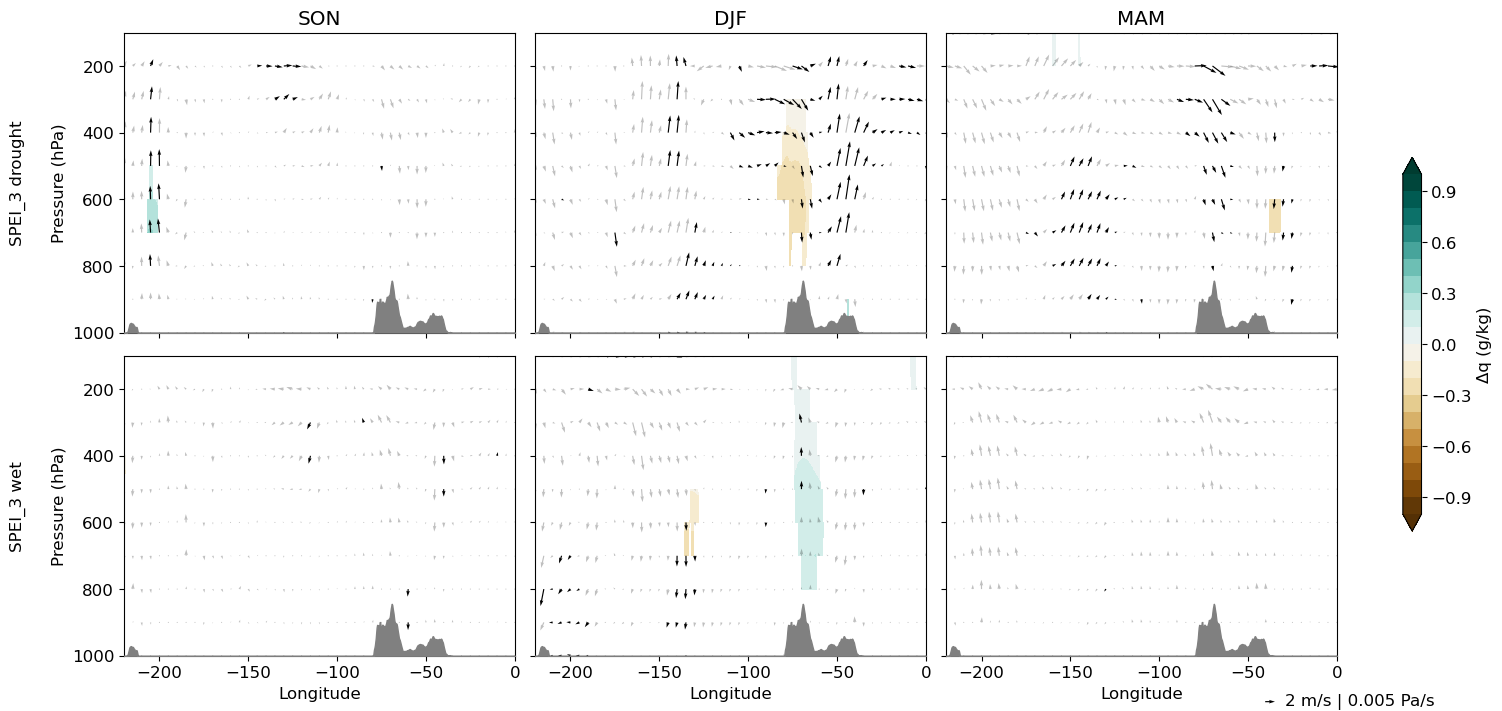

In [86]:
drought_type = 'SPEI_3'

plot_xsection_composite_mean_drought(drought_type, drought_threshold, wet_threshold, vhi_drought_threshold, vhi_wet_threshold)

SON: Climatology n = 108, SPEI_3 drought n = 15, SPEI_3 wet n = 14
    mean SPEI: all SON = -0.01, SPEI_3 drought = -1.42, SPEI_3 wet = 1.32


DJF: Climatology n = 108, SPEI_3 drought n = 14, SPEI_3 wet n = 15
    mean SPEI: all DJF = -0.00, SPEI_3 drought = -1.29, SPEI_3 wet = 1.38
MAM: Climatology n = 108, SPEI_3 drought n = 14, SPEI_3 wet n = 12
    mean SPEI: all MAM = -0.01, SPEI_3 drought = -1.49, SPEI_3 wet = 1.29


(<Figure size 1500x700 with 7 Axes>,
 array([[<Axes: title={'center': 'SON'}, ylabel='Pressure (hPa)'>,
         <Axes: title={'center': 'DJF'}>, <Axes: title={'center': 'MAM'}>],
        [<Axes: xlabel='Longitude', ylabel='Pressure (hPa)'>,
         <Axes: xlabel='Longitude'>, <Axes: xlabel='Longitude'>]],
       dtype=object))

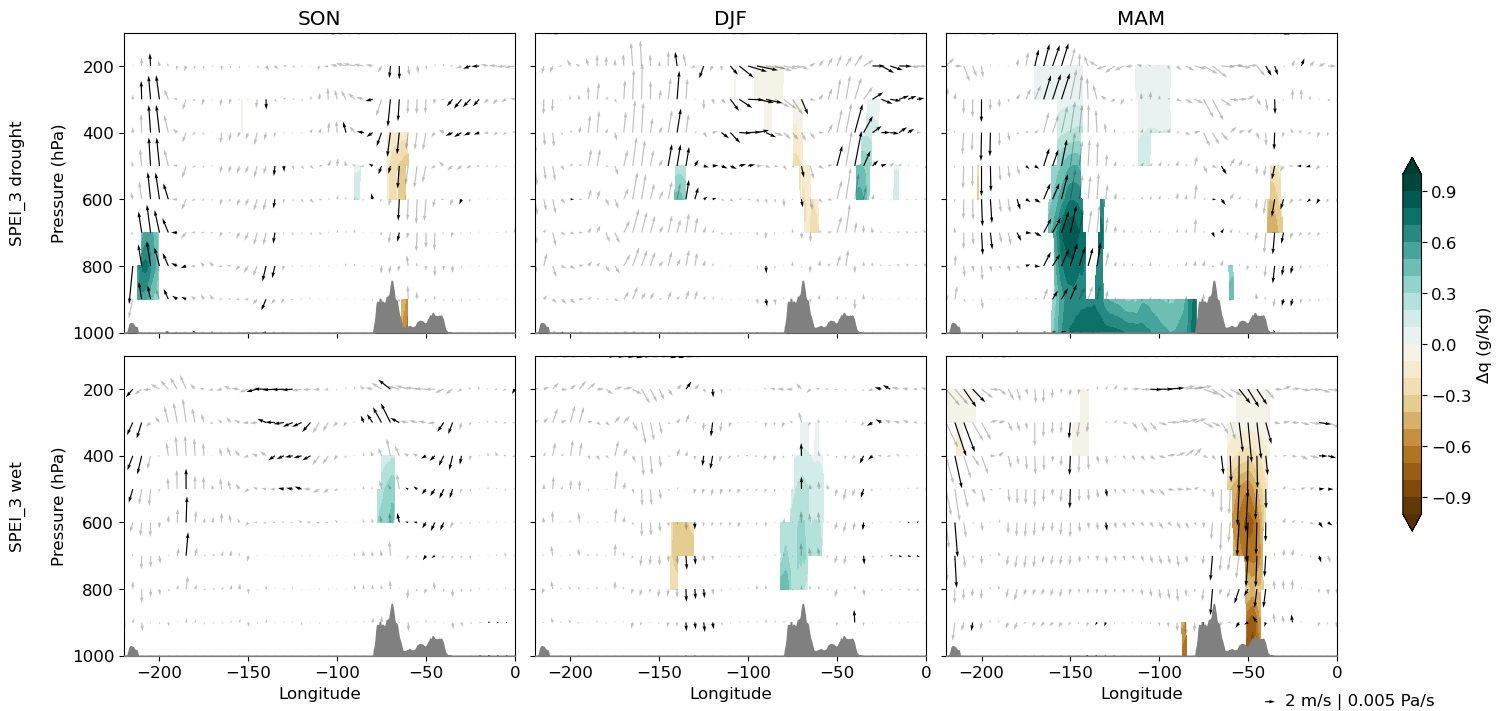

In [87]:
plot_xsection_composite_mean_drought(drought_type, -1, 1, vhi_drought_threshold, vhi_wet_threshold)

### Soil moisture drought (SSMI <= -1 or -0.5) and wet (SSMI >= 1 or 0.5) months vs climatology

SON: Climatology n = 108, SSMI_3 drought n = 34, SSMI_3 wet n = 32
    mean SPEI: all SON = -0.01, SSMI_3 drought = -0.70, SSMI_3 wet = 0.64
DJF: Climatology n = 108, SSMI_3 drought n = 33, SSMI_3 wet n = 33
    mean SPEI: all DJF = -0.00, SSMI_3 drought = -0.45, SSMI_3 wet = 0.65
MAM: Climatology n = 108, SSMI_3 drought n = 27, SSMI_3 wet n = 28
    mean SPEI: all MAM = -0.01, SSMI_3 drought = -0.94, SSMI_3 wet = 0.65


(<Figure size 1500x700 with 7 Axes>,
 array([[<Axes: title={'center': 'SON'}, ylabel='Pressure (hPa)'>,
         <Axes: title={'center': 'DJF'}>, <Axes: title={'center': 'MAM'}>],
        [<Axes: xlabel='Longitude', ylabel='Pressure (hPa)'>,
         <Axes: xlabel='Longitude'>, <Axes: xlabel='Longitude'>]],
       dtype=object))

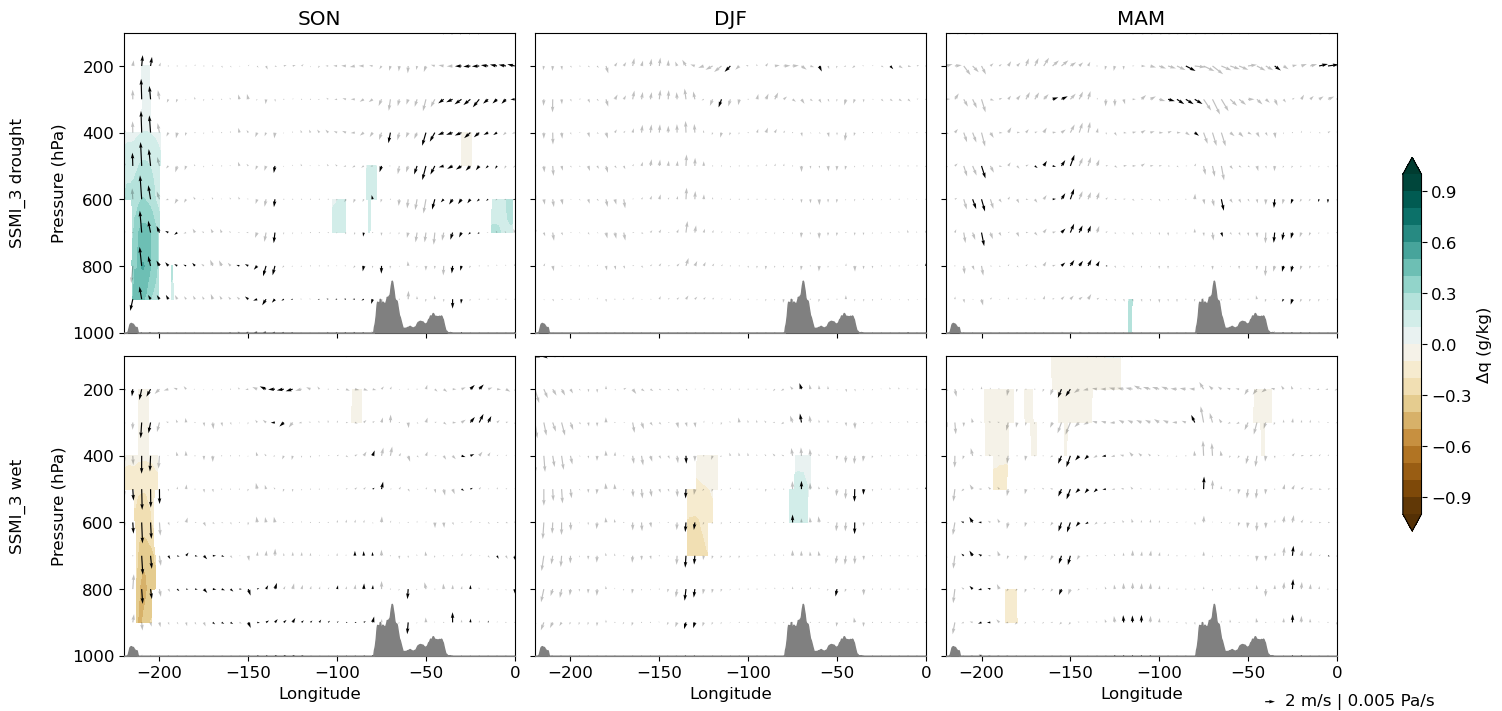

In [88]:
drought_type = 'SSMI_3'

plot_xsection_composite_mean_drought(drought_type, drought_threshold, wet_threshold, vhi_drought_threshold, vhi_wet_threshold)

SON: Climatology n = 108, SSMI_3 drought n = 15, SSMI_3 wet n = 17
    mean SPEI: all SON = -0.01, SSMI_3 drought = -0.97, SSMI_3 wet = 0.81
DJF: Climatology n = 108, SSMI_3 drought n = 10, SSMI_3 wet n = 12
    mean SPEI: all DJF = -0.00, SSMI_3 drought = -0.61, SSMI_3 wet = 0.74
MAM: Climatology n = 108, SSMI_3 drought n = 15, SSMI_3 wet n = 17
    mean SPEI: all MAM = -0.01, SSMI_3 drought = -1.14, SSMI_3 wet = 0.68


(<Figure size 1500x700 with 7 Axes>,
 array([[<Axes: title={'center': 'SON'}, ylabel='Pressure (hPa)'>,
         <Axes: title={'center': 'DJF'}>, <Axes: title={'center': 'MAM'}>],
        [<Axes: xlabel='Longitude', ylabel='Pressure (hPa)'>,
         <Axes: xlabel='Longitude'>, <Axes: xlabel='Longitude'>]],
       dtype=object))

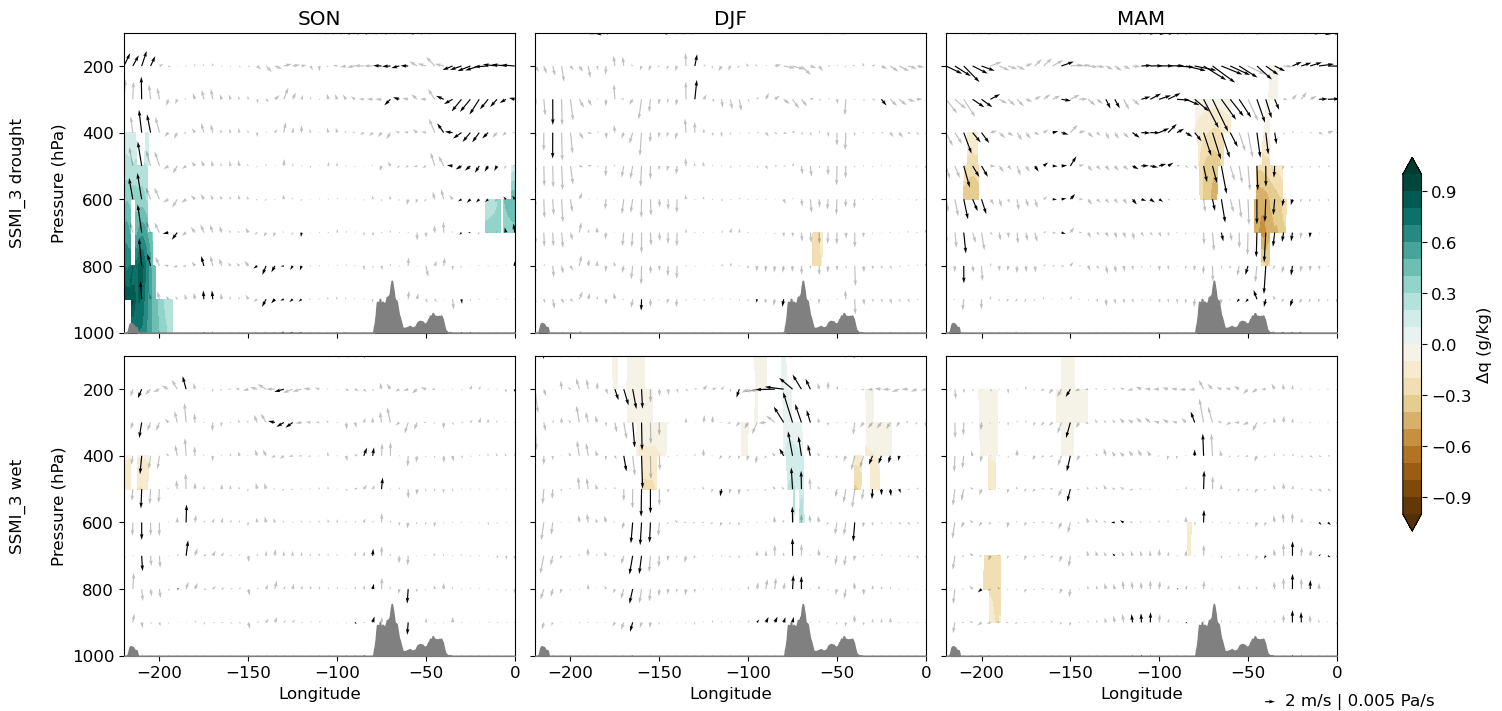

In [89]:
drought_type = 'SSMI_3'

plot_xsection_composite_mean_drought(drought_type, -1, 1, vhi_drought_threshold, vhi_wet_threshold)

### Vegetation drought (VHI <= 35 or 40) and wet (VHI >= 55 or 50) months vs climatology

SON: Climatology n = 108, VHI drought n = 39, VHI wet n = 29
    mean SPEI: all SON = -0.01, VHI drought = -0.62, VHI wet = 0.63
DJF: Climatology n = 108, VHI drought n = 43, VHI wet n = 17
    mean SPEI: all DJF = -0.00, VHI drought = -0.47, VHI wet = 0.59
MAM: Climatology n = 108, VHI drought n = 36, VHI wet n = 28
    mean SPEI: all MAM = -0.01, VHI drought = -0.70, VHI wet = 0.69


(<Figure size 1500x700 with 7 Axes>,
 array([[<Axes: title={'center': 'SON'}, ylabel='Pressure (hPa)'>,
         <Axes: title={'center': 'DJF'}>, <Axes: title={'center': 'MAM'}>],
        [<Axes: xlabel='Longitude', ylabel='Pressure (hPa)'>,
         <Axes: xlabel='Longitude'>, <Axes: xlabel='Longitude'>]],
       dtype=object))

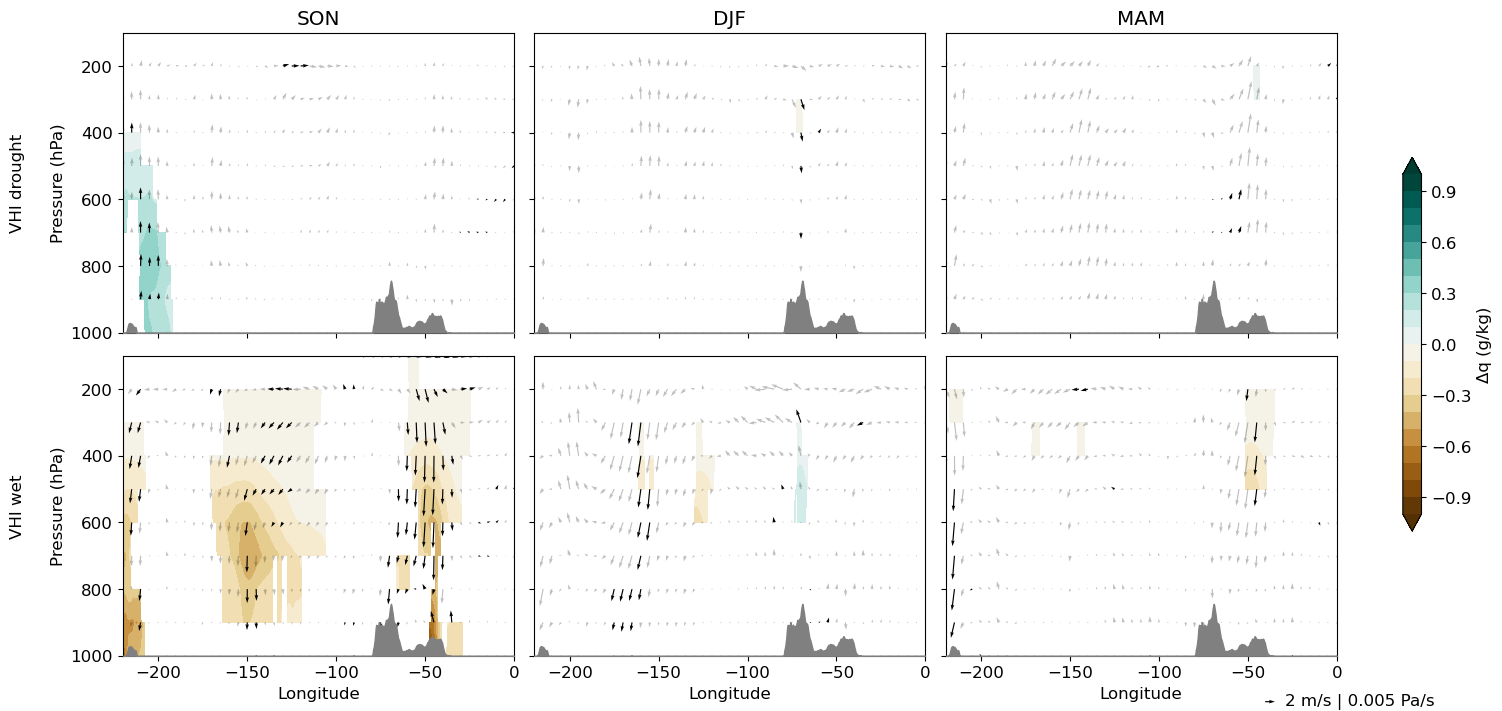

In [90]:
drought_type = 'VHI'

plot_xsection_composite_mean_drought(drought_type, drought_threshold, wet_threshold, vhi_drought_threshold, vhi_wet_threshold)

SON: Climatology n = 108, VHI drought n = 18, VHI wet n = 18
    mean SPEI: all SON = -0.01, VHI drought = -0.86, VHI wet = 0.76
DJF: Climatology n = 108, VHI drought n = 16, VHI wet n = 2
    mean SPEI: all DJF = -0.00, VHI drought = -0.83, VHI wet = 0.47
MAM: Climatology n = 108, VHI drought n = 12, VHI wet n = 21
    mean SPEI: all MAM = -0.01, VHI drought = -1.03, VHI wet = 0.73


(<Figure size 1500x700 with 7 Axes>,
 array([[<Axes: title={'center': 'SON'}, ylabel='Pressure (hPa)'>,
         <Axes: title={'center': 'DJF'}>, <Axes: title={'center': 'MAM'}>],
        [<Axes: xlabel='Longitude', ylabel='Pressure (hPa)'>,
         <Axes: xlabel='Longitude'>, <Axes: xlabel='Longitude'>]],
       dtype=object))

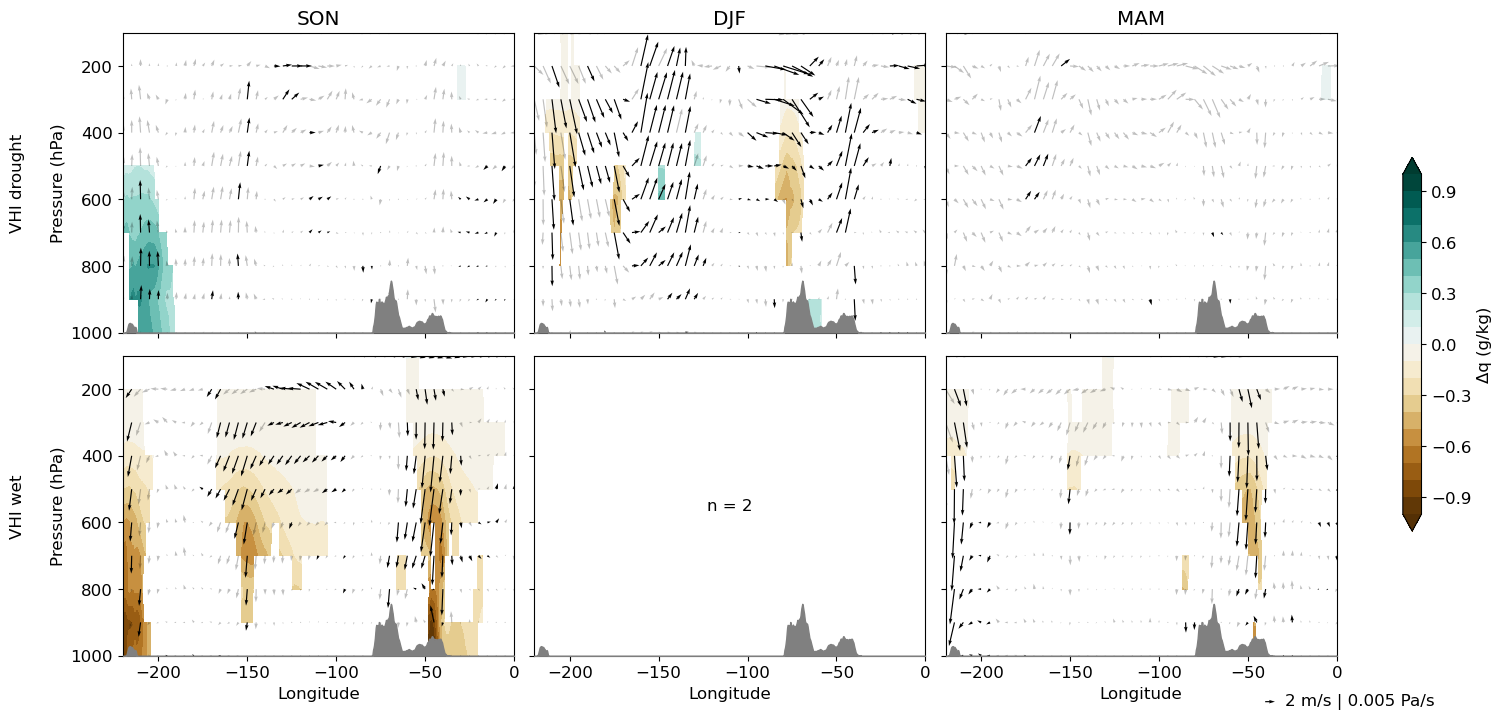

In [91]:
drought_type = 'VHI'

plot_xsection_composite_mean_drought(drought_type, drought_threshold, wet_threshold, 35, 55)

### Anomalies during El Niño and La Niña vs climatology (for reference)

In [ ]:
def plot_xsection_composite_mean_driver(driver):
    d = driver_dates[driver]
    seasons = {'SON': [9, 10, 11], 'DJF': [12, 1, 2], 'MAM': [3, 4, 5]}

    def composite(da, dates, months):
        da = da.sel(time = da.time.isin(dates) & da.time.dt.month.isin(months), pressure_level = slice(1000, 100)) #use 1000-100 hPa range
        return da.mean('time'), da.time.size, da  # also return the individual months for the t-test

    def p_value(samples, clim):
        # one-sample Student's t-test: is the phase mean different from the climatological mean?
        return stats.ttest_1samp(samples.values, clim.values, axis = 0).pvalue

    def clim_mean(da, months):
        da = da.sel(time = da.time.dt.month.isin(months), pressure_level = slice(1000, 100)) #use 1000-100 hPa range
        return da.mean('time'), da.time.size

    fig, axes = plt.subplots(2, 3, figsize = (15,7), sharex = True, sharey = True, constrained_layout = True)
    quiver_scale = 2
    omega_scale = 400

    for j, (season, months) in enumerate(seasons.items()):
        #use climatology as comparison for the anomalies
        q_neu, n_neu = clim_mean(sh_xsection.q * 1000, months)  # g/kg
        u_neu, _ = clim_mean(u_wind_xsection.u, months)
        w_neu, _ = clim_mean(w_wind_xsection.w, months)
        print(f"{season}: Climatology n = {n_neu}", end = '')

        for i, (phase, label) in enumerate(zip(['neg', 'pos'], [d['labels'][0], d['labels'][2]])):
            q, n, q_samples = composite(sh_xsection.q * 1000, d[phase], months)
            u, _, u_samples = composite(u_wind_xsection.u, d[phase], months)
            w, _, w_samples = composite(w_wind_xsection.w, d[phase], months)

            # significance at 95% (p < 0.05)
            q_sig = p_value(q_samples, q_neu) < 0.05
            wind_sig = (p_value(u_samples, u_neu) < 0.05) | (p_value(w_samples, w_neu) < 0.05)  # arrow significant if u or omega is

            q, u, w = q - q_neu, u - u_neu, w - w_neu
            print(f", {label} n = {n}", end = '')

            ax = axes[i, j]
            # non-significant shading masked out, so it shows as white
            cf = ax.contourf(q.x, q.pressure_level, q.where(q_sig), levels = np.linspace(-1, 1, 21), cmap = 'BrBG', extend = 'both')

            # every 5 deg; omega x -omega_scale so it is visible next to u and upward motion points up
            x, p = u.x[::20], u.pressure_level
            U, W, sig = u[:, ::20].values, -omega_scale * w[:, ::20].values, wind_sig[:, ::20]
            quiv = ax.quiver(x, p, np.where(sig, U, np.nan), np.where(sig, W, np.nan), scale = 80, width = 0.003)
            ax.quiver(x, p, np.where(sig, np.nan, U), np.where(sig, np.nan, W), scale = 80, width = 0.003, alpha = 0.25)

            if j == 0:
                ax.text(-0.25, 0.5, label, transform=ax.transAxes,
                rotation=90, va='center', ha='right')
            if i == 0:
                ax.set_title(season)

            ax.fill_between(sp_xsection.x, sp_xsection.sp / 100, 1000, color = 'grey', zorder = 3)  # sp in Pa → hPa
            ax.set_ylim(100,1000)
 
        print()

        # mean value of the index in this season: all months, then only the La Niña / El Niño months
        in_season = driver_comp.index.month.isin(months)
        for col in d['index']:
            means = [driver_comp.loc[in_season, col].mean()]
            for phase in ['neg', 'pos']:
                means.append(driver_comp.loc[d[phase][d[phase].month.isin(months)], col].mean())
            print(f"    mean {col}: all {season} = {means[0]:.2f}, {d['labels'][0]} = {means[1]:.2f}, {d['labels'][2]} = {means[2]:.2f}")


    for ax in axes[:, 0]:
        ax.set_ylabel('Pressure (hPa)')
    for ax in axes[1, :]:
        ax.set_xlabel('Longitude')
    axes[0, 0].invert_yaxis()
    omega_length = np.around(quiver_scale / omega_scale, decimals=3)
    axes[1, 2].quiverkey(quiv, X = 1, Y = -0.1, U = quiver_scale, label = f"{quiver_scale} m/s | {omega_length} Pa/s", labelpos = 'E')
    fig.colorbar(cf, ax = axes, label = 'Δq (g/kg)', shrink = 0.6)

    return fig, axes

SON: Climatology n = 108, La Niña (Niño 3.4) n = 33, El Niño (Niño 3.4) n = 33
    mean nino34: all SON = 0.03, La Niña (Niño 3.4) = -1.04, El Niño (Niño 3.4) = 1.19
DJF: Climatology n = 108, La Niña (Niño 3.4) n = 39, El Niño (Niño 3.4) n = 36
    mean nino34: all DJF = -0.01, La Niña (Niño 3.4) = -1.12, El Niño (Niño 3.4) = 1.20
MAM: Climatology n = 108, La Niña (Niño 3.4) n = 24, El Niño (Niño 3.4) n = 21
    mean nino34: all MAM = 0.02, La Niña (Niño 3.4) = -0.86, El Niño (Niño 3.4) = 1.02


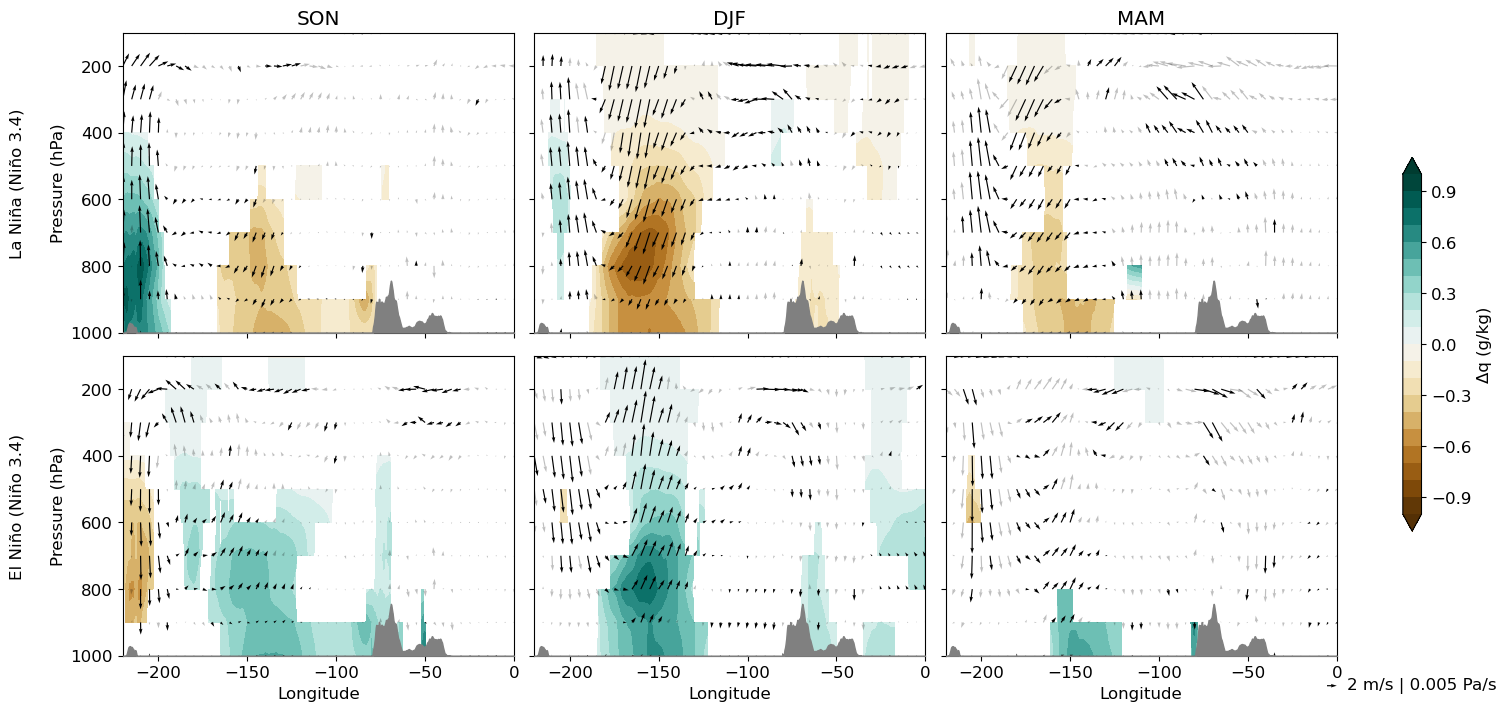

In [93]:
fig, axes = plot_xsection_composite_mean_driver('nino34')

SON: Climatology n = 108, La Niña (Niño 1+2) n = 39, El Niño (Niño 1+2) n = 19
    mean nino12: all SON = -0.11, La Niña (Niño 1+2) = -1.02, El Niño (Niño 1+2) = 1.60
DJF: Climatology n = 108, La Niña (Niño 1+2) n = 30, El Niño (Niño 1+2) n = 19
    mean nino12: all DJF = -0.04, La Niña (Niño 1+2) = -0.86, El Niño (Niño 1+2) = 1.34
MAM: Climatology n = 108, La Niña (Niño 1+2) n = 36, El Niño (Niño 1+2) n = 22
    mean nino12: all MAM = -0.05, La Niña (Niño 1+2) = -0.97, El Niño (Niño 1+2) = 1.39


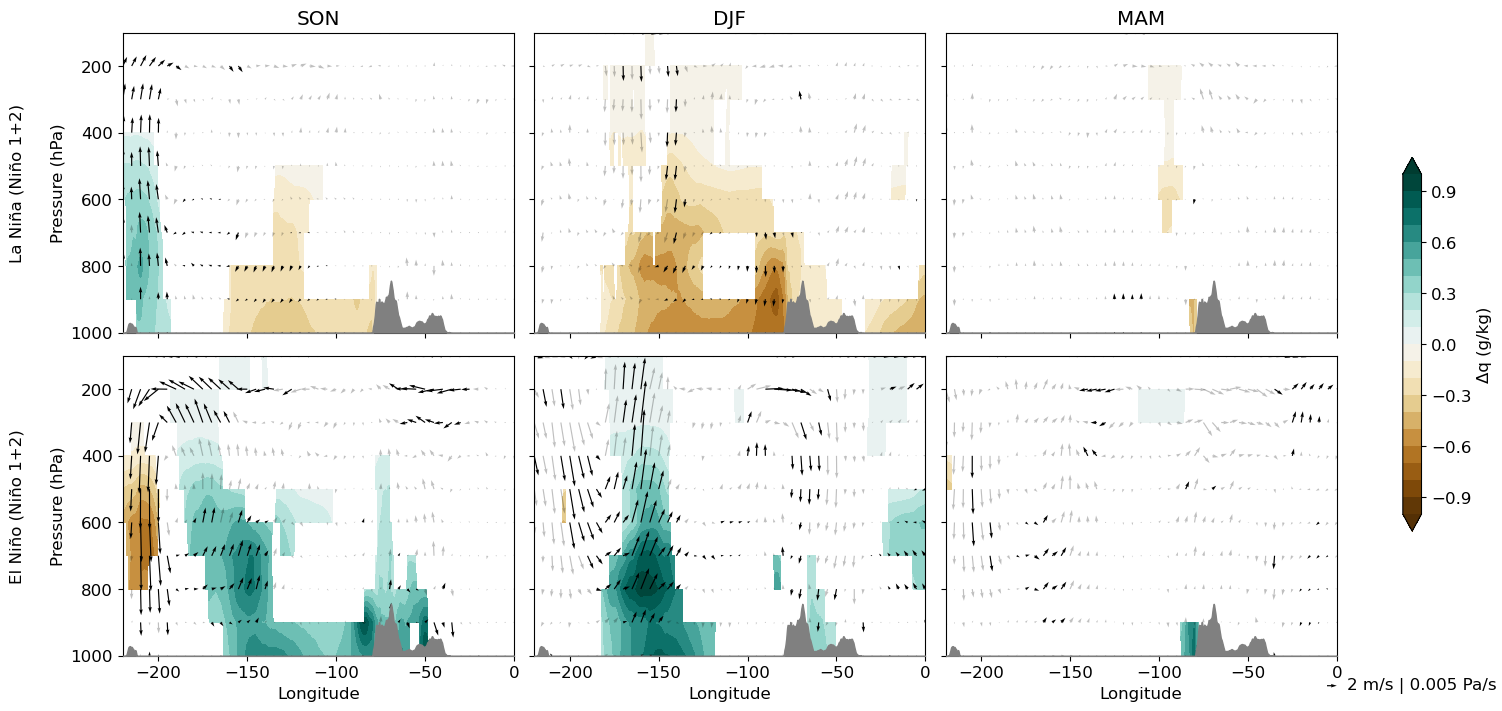

In [94]:
fig, axes = plot_xsection_composite_mean_driver('nino12')

### Anomalies during El Niño and La Niña, with in phase PDO vs climatology (for reference)

SON: Climatology n = 108, Cold PDO + La Niña (Niño 3.4) n = 23, Warm PDO + El Niño (Niño 3.4) n = 13
    mean pdo: all SON = -0.50, Cold PDO + La Niña (Niño 3.4) = -1.64, Warm PDO + El Niño (Niño 3.4) = 1.20
    mean nino34: all SON = 0.03, Cold PDO + La Niña (Niño 3.4) = -1.09, Warm PDO + El Niño (Niño 3.4) = 1.58
DJF: Climatology n = 108, Cold PDO + La Niña (Niño 3.4) n = 21, Warm PDO + El Niño (Niño 3.4) n = 15
    mean pdo: all DJF = -0.24, Cold PDO + La Niña (Niño 3.4) = -1.51, Warm PDO + El Niño (Niño 3.4) = 1.35
    mean nino34: all DJF = -0.01, Cold PDO + La Niña (Niño 3.4) = -1.36, Warm PDO + El Niño (Niño 3.4) = 1.39
MAM: Climatology n = 108, Cold PDO + La Niña (Niño 3.4) n = 18, Warm PDO + El Niño (Niño 3.4) n = 12
    mean pdo: all MAM = -0.13, Cold PDO + La Niña (Niño 3.4) = -1.18, Warm PDO + El Niño (Niño 3.4) = 1.27
    mean nino34: all MAM = 0.02, Cold PDO + La Niña (Niño 3.4) = -0.88, Warm PDO + El Niño (Niño 3.4) = 1.12


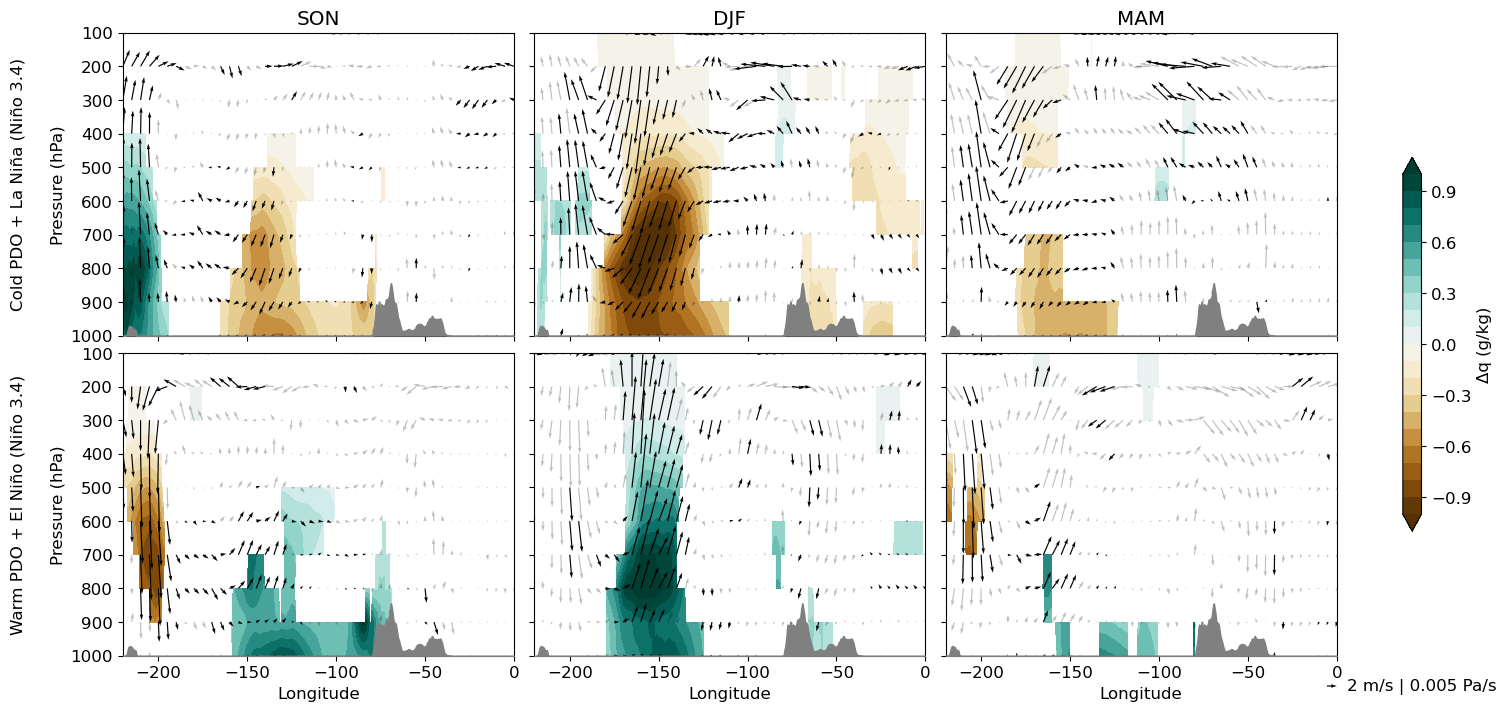

In [95]:
fig, axes = plot_xsection_composite_mean_driver('pdo_nino34')

SON: Climatology n = 108, Cold PDO + La Niña (Niño 1+2) n = 30, Warm PDO + El Niño (Niño 1+2) n = 11
    mean pdo: all SON = -0.50, Cold PDO + La Niña (Niño 1+2) = -1.56, Warm PDO + El Niño (Niño 1+2) = 1.17
    mean nino12: all SON = -0.11, Cold PDO + La Niña (Niño 1+2) = -1.07, Warm PDO + El Niño (Niño 1+2) = 2.07
DJF: Climatology n = 108, Cold PDO + La Niña (Niño 1+2) n = 11, Warm PDO + El Niño (Niño 1+2) n = 10
    mean pdo: all DJF = -0.24, Cold PDO + La Niña (Niño 1+2) = -1.57, Warm PDO + El Niño (Niño 1+2) = 1.27
    mean nino12: all DJF = -0.04, Cold PDO + La Niña (Niño 1+2) = -0.90, Warm PDO + El Niño (Niño 1+2) = 1.75
MAM: Climatology n = 108, Cold PDO + La Niña (Niño 1+2) n = 12, Warm PDO + El Niño (Niño 1+2) n = 13
    mean pdo: all MAM = -0.13, Cold PDO + La Niña (Niño 1+2) = -1.05, Warm PDO + El Niño (Niño 1+2) = 1.19
    mean nino12: all MAM = -0.05, Cold PDO + La Niña (Niño 1+2) = -0.94, Warm PDO + El Niño (Niño 1+2) = 1.39


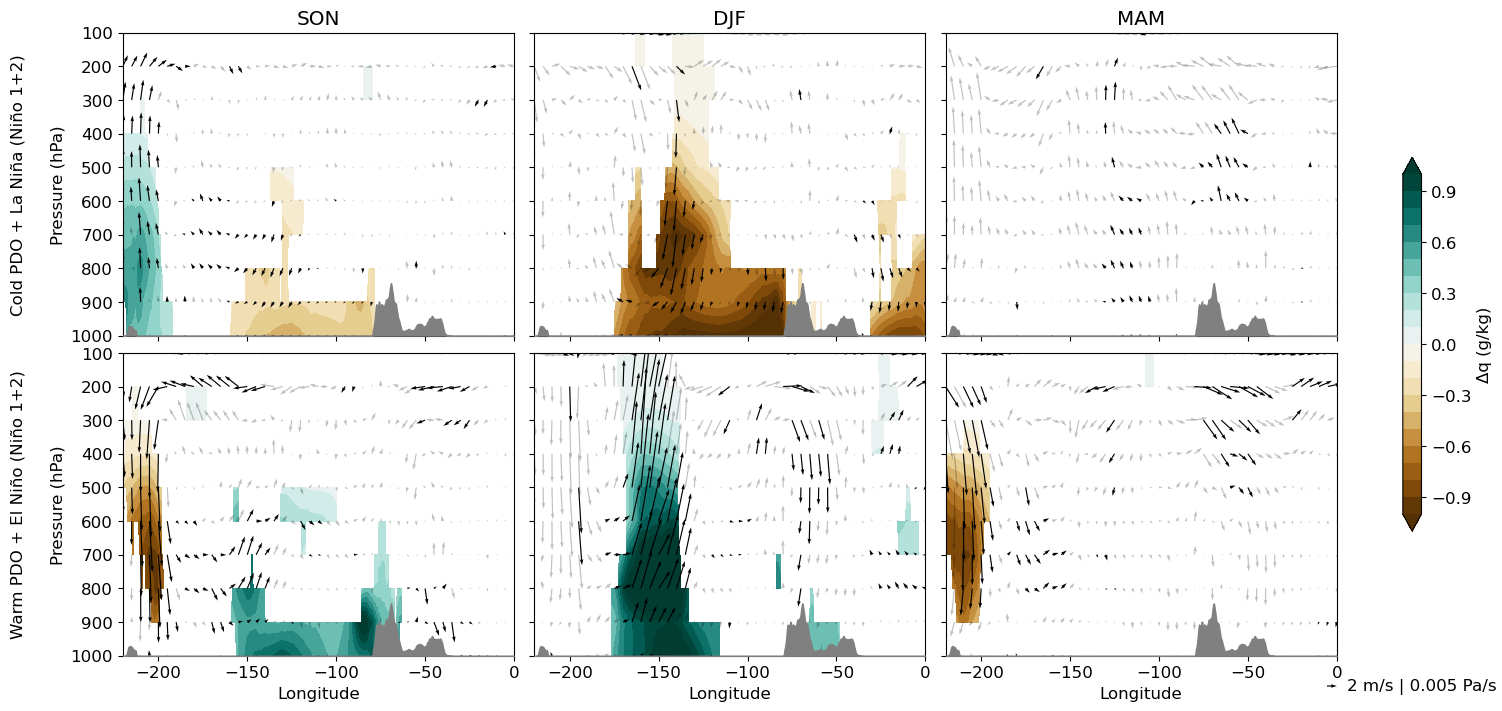

In [96]:
fig, axes = plot_xsection_composite_mean_driver('pdo_nino12')

### Composite: Meteorological drought under different ENSO conditions vs climatology

In [ ]:
def plot_xsection_composite_mean_drought_driver(driver, drought_type, threshold, wet_threshold, vhi_threshold, vhi_wet):
    # rows: drought and wet months during the negative phase of the driver (e.g. La Niña), then during the positive phase (e.g. El Niño)
    d = driver_dates[driver]
    drought_df = calculate_drought_months(threshold, vhi_threshold)
    wet_df = calculate_wet_months(wet_threshold, vhi_wet)
    drought_dates = pd.DatetimeIndex(drought_df.loc[drought_df[drought_type], 'time'])
    wet_dates = pd.DatetimeIndex(wet_df.loc[wet_df[drought_type], 'time'])
    spei_series = drought_comp['SPEI_3']  # regional mean SPEI

    rows = [(drought_dates.intersection(d['neg']), f"{drought_type.upper()} drought\n{d['labels'][0]}"),
            (wet_dates.intersection(d['neg']), f"{drought_type.upper()} wet\n{d['labels'][0]}"),
            (drought_dates.intersection(d['pos']), f"{drought_type.upper()} drought\n{d['labels'][2]}"),
            (wet_dates.intersection(d['pos']), f"{drought_type.upper()} wet\n{d['labels'][2]}")]

    seasons = {'SON': [9, 10, 11], 'DJF': [12, 1, 2], 'MAM': [3, 4, 5]}

    def composite(da, dates, months):
        da = da.sel(time = da.time.isin(dates) & da.time.dt.month.isin(months), pressure_level = slice(1000, 100)) #use 1000-100 hPa range
        return da.mean('time'), da.time.size, da  # also return the individual months for the t-test

    def p_value(samples, clim):
        # one-sample Student's t-test: is the composite mean different from the climatological mean?
        return stats.ttest_1samp(samples.values, clim.values, axis = 0).pvalue

    def clim_mean(da, months):
        da = da.sel(time = da.time.dt.month.isin(months), pressure_level = slice(1000, 100)) #use 1000-100 hPa range
        return da.mean('time'), da.time.size

    fig, axes = plt.subplots(4, 3, figsize = (15,13), sharex = True, sharey = True, constrained_layout = True)
    quiver_scale = 2
    omega_scale = 400
    quiv = None  # stays None if every panel has too few months

    for j, (season, months) in enumerate(seasons.items()):
        #get climatological mean for anomaly
        q_clim, n_clim = clim_mean(sh_xsection.q * 1000, months)  # g/kg
        u_clim, _ = clim_mean(u_wind_xsection.u, months)
        w_clim, _ = clim_mean(w_wind_xsection.w, months)
        print(f"{season}: Climatology n = {n_clim}, mean SPEI = {spei_series[spei_series.index.month.isin(months)].mean():.2f}")

        for i, (dates, label) in enumerate(rows):
            ax = axes[i, j]
            if j == 0:
                ax.text(-0.25, 0.5, label, transform=ax.transAxes,
                rotation=90, va='center', ha='right')
            if i == 0:
                ax.set_title(season)
            ax.fill_between(sp_xsection.x, sp_xsection.sp / 100, 1000, color = 'grey', zorder = 3)  # sp in Pa → hPa
            ax.set_ylim(100,1000)

            # mean SPEI and driver index for the months in this panel
            season_dates = dates[dates.month.isin(months)]
            index_means = ', '.join(f"mean {col} = {driver_comp.loc[season_dates, col].mean():.2f}" for col in d['index'])
            print(f"    {label.replace(chr(10), ' + ')}: n = {len(season_dates)}, mean SPEI = {spei_series.loc[season_dates].mean():.2f}, {index_means}")

            if len(season_dates) < 3:  # too few months for a composite / t-test
                ax.text(0.5, 0.5, f'n = {len(season_dates)}', transform = ax.transAxes, ha = 'center', va = 'center')
                continue

            q, n, q_samples = composite(sh_xsection.q * 1000, season_dates, months)
            u, _, u_samples = composite(u_wind_xsection.u, season_dates, months)
            w, _, w_samples = composite(w_wind_xsection.w, season_dates, months)

            # significance at 95% (p < 0.05)
            q_sig = p_value(q_samples, q_clim) < 0.05
            wind_sig = (p_value(u_samples, u_clim) < 0.05) | (p_value(w_samples, w_clim) < 0.05)  # arrow significant if u or omega is

            q, u, w = q - q_clim, u - u_clim, w - w_clim

            # non-significant shading masked out, so it shows as white
            cf = ax.contourf(q.x, q.pressure_level, q.where(q_sig), levels = np.linspace(-1, 1, 21), cmap = 'BrBG', extend = 'both')

            # every 5 deg; omega x -omega_scale so it is visible next to u and upward motion points up
            x, p = u.x[::20], u.pressure_level
            U, W, sig = u[:, ::20].values, -omega_scale * w[:, ::20].values, wind_sig[:, ::20]
            quiv = ax.quiver(x, p, np.where(sig, U, np.nan), np.where(sig, W, np.nan), scale = 80, width = 0.003)
            ax.quiver(x, p, np.where(sig, np.nan, U), np.where(sig, np.nan, W), scale = 80, width = 0.003, alpha = 0.25)

    for ax in axes[:, 0]:
        ax.set_ylabel('Pressure (hPa)')
    for ax in axes[-1, :]:
        ax.set_xlabel('Longitude')
    axes[0, 0].invert_yaxis()
    if quiv is not None:
        omega_length = np.around(quiver_scale / omega_scale, decimals=3)
        axes[-1, 2].quiverkey(quiv, X = 0.85, Y = 0.005, U = quiver_scale, label = f"{quiver_scale} m/s | {omega_length} Pa/s", labelpos = 'E', coordinates = 'figure')
        fig.colorbar(cf, ax = axes, label = 'Δq (g/kg)', shrink = 0.6)

    return fig, axes

SON: Climatology n = 108, mean SPEI = -0.01
    SPEI_3 drought + La Niña (Niño 3.4): n = 18, mean SPEI = -1.10, mean nino34 = -1.19
    SPEI_3 wet + La Niña (Niño 3.4): n = 6, mean SPEI = 0.84, mean nino34 = -0.71
    SPEI_3 drought + El Niño (Niño 3.4): n = 7, mean SPEI = -0.97, mean nino34 = 1.34
    SPEI_3 wet + El Niño (Niño 3.4): n = 12, mean SPEI = 1.18, mean nino34 = 1.07
DJF: Climatology n = 108, mean SPEI = -0.00
    SPEI_3 drought + La Niña (Niño 3.4): n = 9, mean SPEI = -0.88, mean nino34 = -1.29
    SPEI_3 wet + La Niña (Niño 3.4): n = 6, mean SPEI = 0.92, mean nino34 = -0.95
    SPEI_3 drought + El Niño (Niño 3.4): n = 9, mean SPEI = -1.11, mean nino34 = 1.38
    SPEI_3 wet + El Niño (Niño 3.4): n = 12, mean SPEI = 1.01, mean nino34 = 1.04
MAM: Climatology n = 108, mean SPEI = -0.01
    SPEI_3 drought + La Niña (Niño 3.4): n = 2, mean SPEI = -0.88, mean nino34 = -0.77
    SPEI_3 wet + La Niña (Niño 3.4): n = 15, mean SPEI = 0.95, mean nino34 = -0.90
    SPEI_3 drought + El

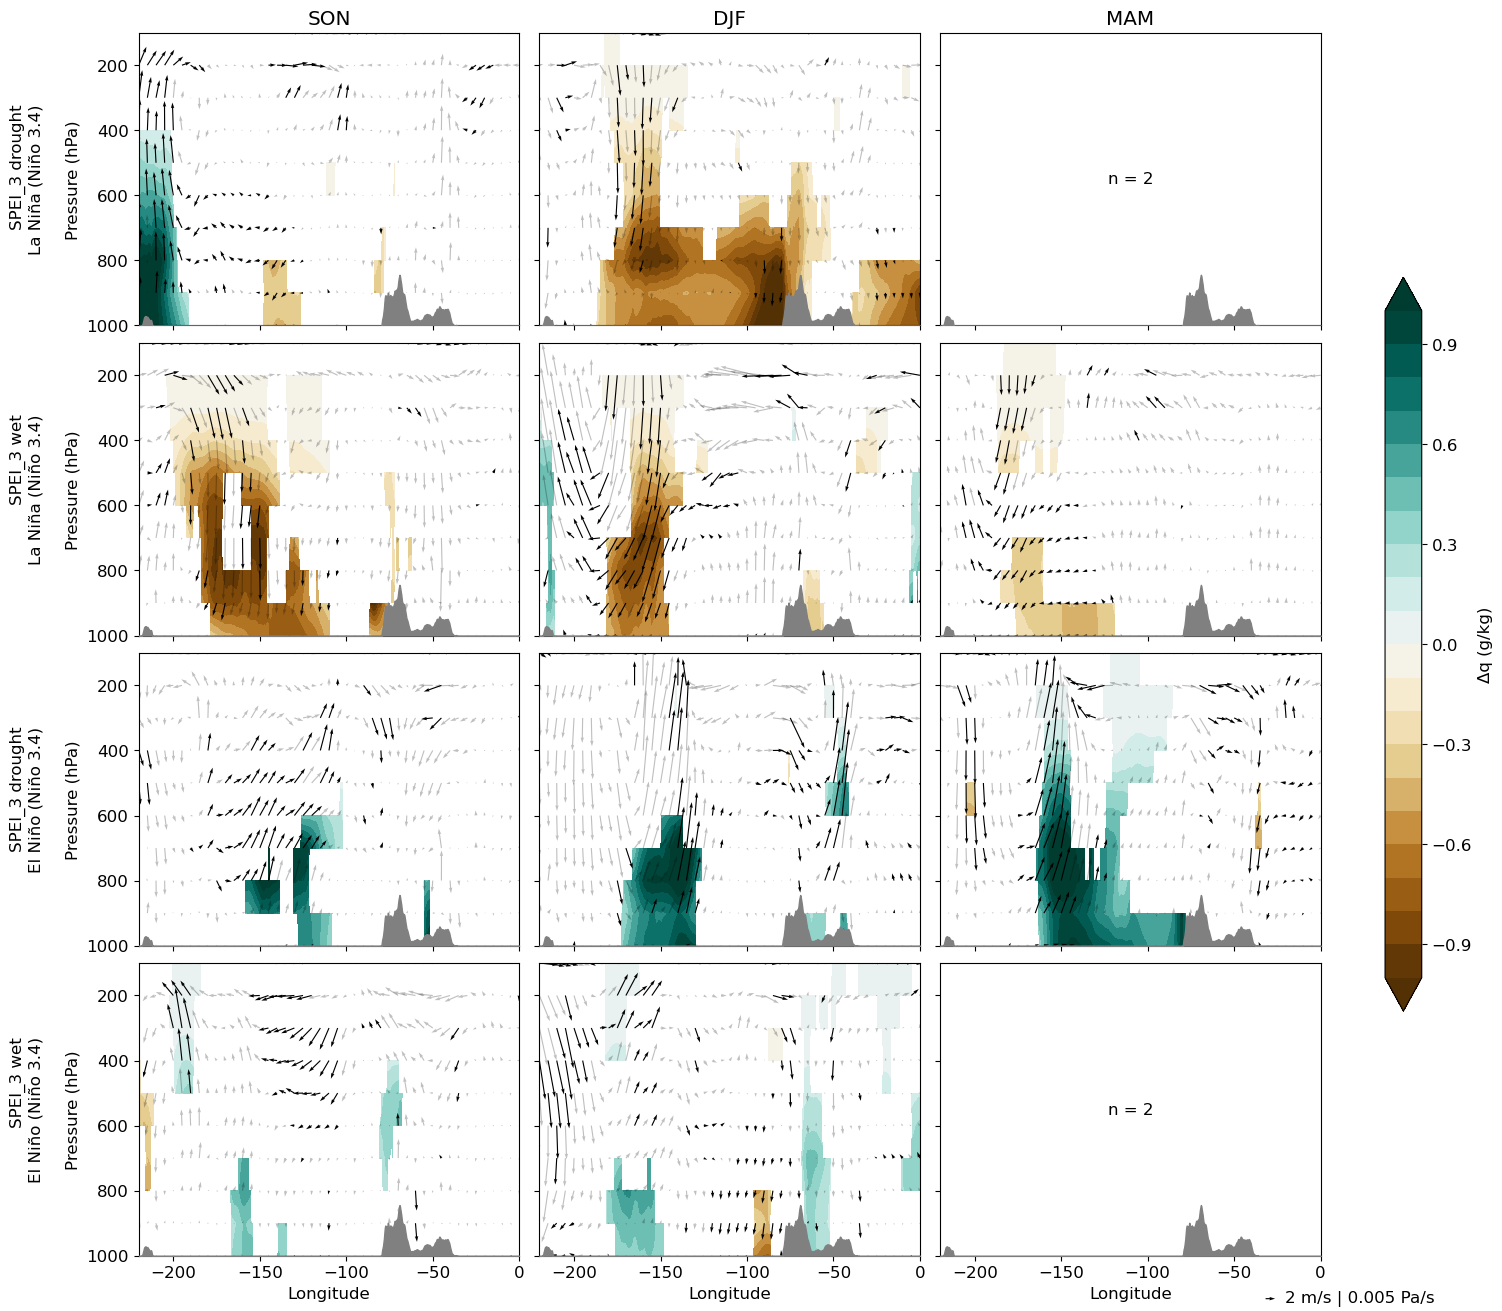

In [98]:
drought_type = 'SPEI_3'

fig, axes = plot_xsection_composite_mean_drought_driver('nino34', drought_type, drought_threshold, wet_threshold, vhi_drought_threshold, vhi_wet_threshold)

check which months are used

In [ ]:
# uses drought_type, thresholds etc. from the cell above
driver, case, phase, months = 'nino34', 'drought', 'pos', [3, 4, 5]  # e.g. SPEI drought + El Niño (Niño 3.4) in MAM; case 'drought'/'wet', phase 'neg'/'pos'

if case == 'drought':
    df = calculate_drought_months(drought_threshold, vhi_drought_threshold)
else:
    df = calculate_wet_months(wet_threshold, vhi_wet_threshold)
phase_dates = driver_dates[driver][phase]
used = pd.DatetimeIndex(df.loc[df[drought_type], 'time']).intersection(phase_dates)
used = used[used.month.isin(months)]

# group consecutive months of the ENSO phase into events (a gap of a month or more starts a new event)
phase_series = pd.Series(phase_dates, index = phase_dates)
event_id = (phase_series.diff() > pd.Timedelta(days = 31)).cumsum()
event_name = phase_series.groupby(event_id).transform(lambda t: f"{t.iloc[0]:%Y-%m} to {t.iloc[-1]:%Y-%m}")

spei_series = drought_comp['SPEI_3']
used_months = pd.DataFrame({'SPEI': spei_series.loc[used].round(2).values,
                            driver: driver_comp.loc[used, driver].round(2).values,
                            'event': event_name.loc[used].values}, index = used.strftime('%Y-%m'))

print(f"{len(used)} months from {used_months['event'].nunique()} events")
used_months.index

11 months from 4 events


Index(['1987-03', '1987-04', '1987-05', '1992-03', '1992-04', '1992-05',
       '1998-03', '1998-04', '1998-05', '2016-03', '2016-04'],
      dtype='object')

### Composite: Meteorological drought under different ENSO conditions vs conditions during that ENSO phase

In [ ]:
def plot_xsection_drought_driver_vs_driver(driver, drought_type, threshold, wet_threshold, vhi_threshold, vhi_wet):
    # rows: drought and wet months during the negative phase of the driver (e.g. La Niña), then during the positive phase (e.g. El Niño)
    # each row is compared against ALL months of that phase (e.g. La Niña & drought minus La Niña generally), not the climatology
    d = driver_dates[driver]
    drought_df = calculate_drought_months(threshold, vhi_threshold)
    wet_df = calculate_wet_months(wet_threshold, vhi_wet)
    drought_dates = pd.DatetimeIndex(drought_df.loc[drought_df[drought_type], 'time'])
    wet_dates = pd.DatetimeIndex(wet_df.loc[wet_df[drought_type], 'time'])
    spei_series = drought_comp['SPEI_3']  # regional mean SPEI

    # (subset dates, reference phase dates, row label)
    rows = [(drought_dates.intersection(d['neg']), d['neg'], f"{drought_type.upper()} drought\n{d['labels'][0]}"),
            (wet_dates.intersection(d['neg']), d['neg'], f"{drought_type.upper()} wet\n{d['labels'][0]}"),
            (drought_dates.intersection(d['pos']), d['pos'], f"{drought_type.upper()} drought\n{d['labels'][2]}"),
            (wet_dates.intersection(d['pos']), d['pos'], f"{drought_type.upper()} wet\n{d['labels'][2]}")]

    seasons = {'SON': [9, 10, 11], 'DJF': [12, 1, 2], 'MAM': [3, 4, 5]}

    def composite(da, dates, months):
        da = da.sel(time = da.time.isin(dates) & da.time.dt.month.isin(months), pressure_level = slice(1000, 100)) #use 1000-100 hPa range
        return da.mean('time'), da.time.size, da  # also return the individual months for the t-test

    def p_value(samples, ref):
        # one-sample Student's t-test: is the subset mean different from the mean of the whole phase?
        return stats.ttest_1samp(samples.values, ref.values, axis = 0).pvalue

    fig, axes = plt.subplots(4, 3, figsize = (15,13), sharex = True, sharey = True, constrained_layout = True)
    quiver_scale = 2
    omega_scale = 400
    quiv = None  # stays None if every panel has too few months

    for j, (season, months) in enumerate(seasons.items()):
        print(f"{season}:")

        for i, (dates, phase_dates, label) in enumerate(rows):
            ax = axes[i, j]
            if j == 0:
                ax.text(-0.25, 0.5, label, transform=ax.transAxes,
                rotation=90, va='center', ha='right')
            if i == 0:
                ax.set_title(season)
            ax.fill_between(sp_xsection.x, sp_xsection.sp / 100, 1000, color = 'grey', zorder = 3)  # sp in Pa → hPa
            ax.set_ylim(100,1000)

            # n, mean SPEI and mean driver index: subset vs whole phase
            season_dates = dates[dates.month.isin(months)]
            season_phase_dates = phase_dates[phase_dates.month.isin(months)]
            index_means = ', '.join(f"mean {col} = {driver_comp.loc[season_dates, col].mean():.2f} vs {driver_comp.loc[season_phase_dates, col].mean():.2f}" for col in d['index'])
            print(f"    {label.replace(chr(10), ' + ')} vs all {label.split(chr(10))[1]}: "
                  f"n = {len(season_dates)} vs {len(season_phase_dates)}, "
                  f"mean SPEI = {spei_series.loc[season_dates].mean():.2f} vs {spei_series[spei_series.index.isin(season_phase_dates)].mean():.2f}, {index_means}")

            if len(season_dates) < 3:  # too few months for a composite / t-test
                ax.text(0.5, 0.5, f'n = {len(season_dates)}', transform = ax.transAxes, ha = 'center', va = 'center')
                continue

            # reference: all months of this phase in this season
            q_ref, _, _ = composite(sh_xsection.q * 1000, season_phase_dates, months)  # g/kg
            u_ref, _, _ = composite(u_wind_xsection.u, season_phase_dates, months)
            w_ref, _, _ = composite(w_wind_xsection.w, season_phase_dates, months)

            q, n, q_samples = composite(sh_xsection.q * 1000, season_dates, months)
            u, _, u_samples = composite(u_wind_xsection.u, season_dates, months)
            w, _, w_samples = composite(w_wind_xsection.w, season_dates, months)

            # significance at 95% (p < 0.05)
            q_sig = p_value(q_samples, q_ref) < 0.05
            wind_sig = (p_value(u_samples, u_ref) < 0.05) | (p_value(w_samples, w_ref) < 0.05)  # arrow significant if u or omega is

            q, u, w = q - q_ref, u - u_ref, w - w_ref

            # non-significant shading masked out, so it shows as white
            cf = ax.contourf(q.x, q.pressure_level, q.where(q_sig), levels = np.linspace(-1, 1, 21), cmap = 'BrBG', extend = 'both')

            # every 5 deg; omega x -omega_scale so it is visible next to u and upward motion points up
            x, p = u.x[::20], u.pressure_level
            U, W, sig = u[:, ::20].values, -omega_scale * w[:, ::20].values, wind_sig[:, ::20]
            quiv = ax.quiver(x, p, np.where(sig, U, np.nan), np.where(sig, W, np.nan), scale = 80, width = 0.003)
            ax.quiver(x, p, np.where(sig, np.nan, U), np.where(sig, np.nan, W), scale = 80, width = 0.003, alpha = 0.25)

    for ax in axes[:, 0]:
        ax.set_ylabel('Pressure (hPa)')
    for ax in axes[-1, :]:
        ax.set_xlabel('Longitude')
    axes[0, 0].invert_yaxis()
    if quiv is not None:
        omega_length = np.around(quiver_scale / omega_scale, decimals=3)
        axes[-1, 2].quiverkey(quiv, X = 0.85, Y = 0.005, U = quiver_scale, label = f"{quiver_scale} m/s | {omega_length} Pa/s", labelpos = 'E', coordinates = 'figure')
        fig.colorbar(cf, ax = axes, label = 'Δq (g/kg)', shrink = 0.6)

    return fig, axes

SON:
    SPEI_3 drought + La Niña (Niño 3.4) vs all La Niña (Niño 3.4): n = 18 vs 33, mean SPEI = -1.10 vs -0.46, mean nino34 = -1.19 vs -1.04
    SPEI_3 wet + La Niña (Niño 3.4) vs all La Niña (Niño 3.4): n = 6 vs 33, mean SPEI = 0.84 vs -0.46, mean nino34 = -0.71 vs -1.04
    SPEI_3 drought + El Niño (Niño 3.4) vs all El Niño (Niño 3.4): n = 7 vs 33, mean SPEI = -0.97 vs 0.23, mean nino34 = 1.34 vs 1.19
    SPEI_3 wet + El Niño (Niño 3.4) vs all El Niño (Niño 3.4): n = 12 vs 33, mean SPEI = 1.18 vs 0.23, mean nino34 = 1.07 vs 1.19
DJF:
    SPEI_3 drought + La Niña (Niño 3.4) vs all La Niña (Niño 3.4): n = 9 vs 39, mean SPEI = -0.88 vs -0.09, mean nino34 = -1.29 vs -1.12
    SPEI_3 wet + La Niña (Niño 3.4) vs all La Niña (Niño 3.4): n = 6 vs 39, mean SPEI = 0.92 vs -0.09, mean nino34 = -0.95 vs -1.12
    SPEI_3 drought + El Niño (Niño 3.4) vs all El Niño (Niño 3.4): n = 9 vs 36, mean SPEI = -1.11 vs 0.04, mean nino34 = 1.38 vs 1.20
    SPEI_3 wet + El Niño (Niño 3.4) vs all El Niño (N

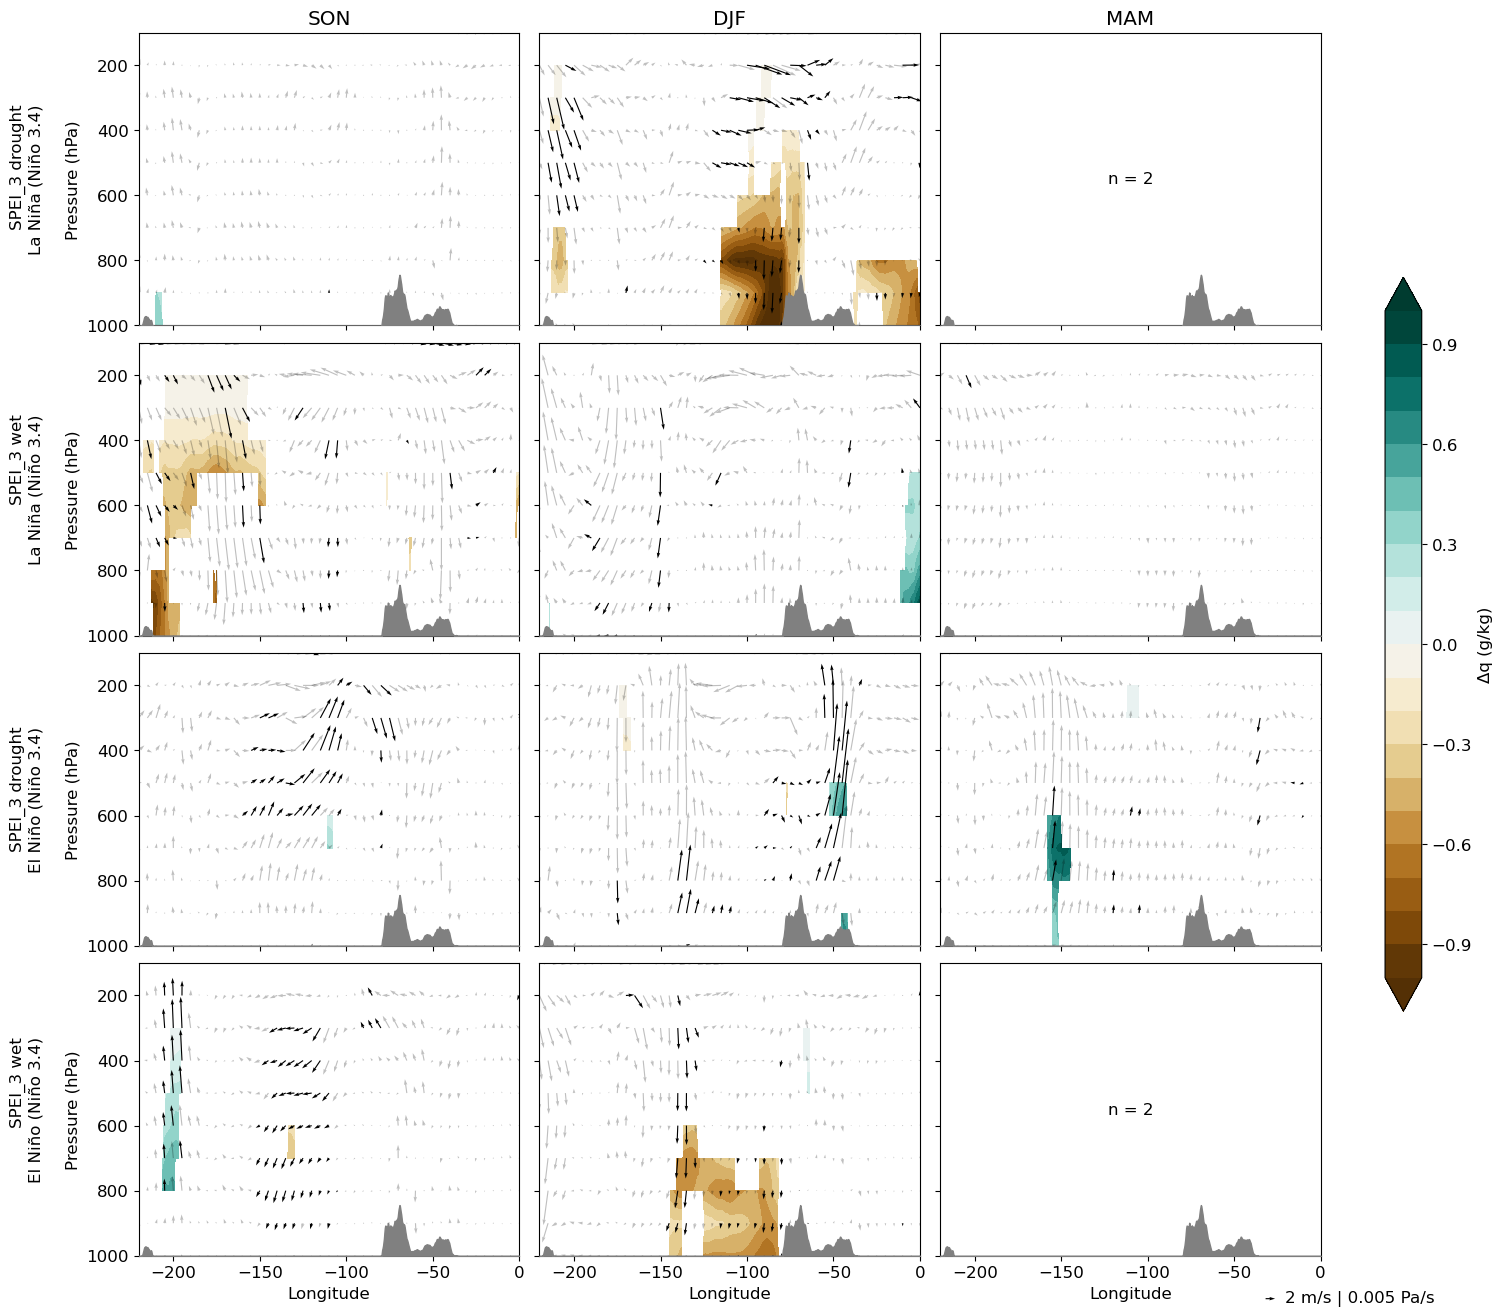

In [101]:
fig, axes = plot_xsection_drought_driver_vs_driver('nino34', drought_type, drought_threshold, wet_threshold, vhi_drought_threshold, vhi_wet_threshold)

### Composite: Meteorological drought under different ENSO conditions vs conditions during drought/wet months in that season generally

In [ ]:
def plot_xsection_drought_driver_vs_drought(driver, drought_type, threshold, wet_threshold, vhi_threshold, vhi_wet):
    # rows: drought and wet months during the negative phase of the driver (e.g. La Niña), then during the positive phase (e.g. El Niño)
    # each row is compared against ALL drought (or wet) months in the season (e.g. La Niña & drought minus drought generally), not the climatology
    d = driver_dates[driver]
    drought_df = calculate_drought_months(threshold, vhi_threshold)
    wet_df = calculate_wet_months(wet_threshold, vhi_wet)
    drought_dates = pd.DatetimeIndex(drought_df.loc[drought_df[drought_type], 'time'])
    wet_dates = pd.DatetimeIndex(wet_df.loc[wet_df[drought_type], 'time'])
    spei_series = drought_comp['SPEI_3']  # regional mean SPEI

    # (subset dates, reference dates, row label)
    rows = [(drought_dates.intersection(d['neg']), drought_dates, f"{drought_type.upper()} drought\n{d['labels'][0]}"),
            (wet_dates.intersection(d['neg']), wet_dates, f"{drought_type.upper()} wet\n{d['labels'][0]}"),
            (drought_dates.intersection(d['pos']), drought_dates, f"{drought_type.upper()} drought\n{d['labels'][2]}"),
            (wet_dates.intersection(d['pos']), wet_dates, f"{drought_type.upper()} wet\n{d['labels'][2]}")]

    seasons = {'SON': [9, 10, 11], 'DJF': [12, 1, 2], 'MAM': [3, 4, 5]}

    def composite(da, dates, months):
        da = da.sel(time = da.time.isin(dates) & da.time.dt.month.isin(months), pressure_level = slice(1000, 100)) #use 1000-100 hPa range
        return da.mean('time'), da.time.size, da  # also return the individual months for the t-test

    def p_value(samples, ref):
        # one-sample Student's t-test: is the subset mean different from the mean of all drought (or wet) months?
        return stats.ttest_1samp(samples.values, ref.values, axis = 0).pvalue

    fig, axes = plt.subplots(4, 3, figsize = (15,13), sharex = True, sharey = True, constrained_layout = True)
    quiver_scale = 2
    omega_scale = 400
    quiv = None  # stays None if every panel has too few months

    for j, (season, months) in enumerate(seasons.items()):
        print(f"{season}:")

        for i, (dates, ref_dates, label) in enumerate(rows):
            ax = axes[i, j]
            if j == 0:
                ax.text(-0.25, 0.5, label, transform=ax.transAxes,
                rotation=90, va='center', ha='right')
            if i == 0:
                ax.set_title(season)
            ax.fill_between(sp_xsection.x, sp_xsection.sp / 100, 1000, color = 'grey', zorder = 3)  # sp in Pa → hPa
            ax.set_ylim(100,1000)

            # n, mean SPEI and mean driver index: subset vs all drought (or wet) months
            season_dates = dates[dates.month.isin(months)]
            season_ref_dates = ref_dates[ref_dates.month.isin(months)]
            index_means = ', '.join(f"mean {col} = {driver_comp.loc[season_dates, col].mean():.2f} vs {driver_comp.loc[season_ref_dates, col].mean():.2f}" for col in d['index'])
            print(f"    {label.replace(chr(10), ' + ')} vs all {label.split(chr(10))[0]}: "
                  f"n = {len(season_dates)} vs {len(season_ref_dates)}, "
                  f"mean SPEI = {spei_series.loc[season_dates].mean():.2f} vs {spei_series[spei_series.index.isin(season_ref_dates)].mean():.2f}, {index_means}")

            if len(season_dates) < 3:  # too few months for a composite / t-test
                ax.text(0.5, 0.5, f'n = {len(season_dates)}', transform = ax.transAxes, ha = 'center', va = 'center')
                continue

            # reference: all drought (or wet) months in this season
            q_ref, _, _ = composite(sh_xsection.q * 1000, season_ref_dates, months)  # g/kg
            u_ref, _, _ = composite(u_wind_xsection.u, season_ref_dates, months)
            w_ref, _, _ = composite(w_wind_xsection.w, season_ref_dates, months)

            q, n, q_samples = composite(sh_xsection.q * 1000, season_dates, months)
            u, _, u_samples = composite(u_wind_xsection.u, season_dates, months)
            w, _, w_samples = composite(w_wind_xsection.w, season_dates, months)

            # significance at 95% (p < 0.05)
            q_sig = p_value(q_samples, q_ref) < 0.05
            wind_sig = (p_value(u_samples, u_ref) < 0.05) | (p_value(w_samples, w_ref) < 0.05)  # arrow significant if u or omega is

            q, u, w = q - q_ref, u - u_ref, w - w_ref

            # non-significant shading masked out, so it shows as white
            cf = ax.contourf(q.x, q.pressure_level, q.where(q_sig), levels = np.linspace(-1, 1, 21), cmap = 'BrBG', extend = 'both')

            # every 5 deg; omega x -omega_scale so it is visible next to u and upward motion points up
            x, p = u.x[::20], u.pressure_level
            U, W, sig = u[:, ::20].values, -omega_scale * w[:, ::20].values, wind_sig[:, ::20]
            quiv = ax.quiver(x, p, np.where(sig, U, np.nan), np.where(sig, W, np.nan), scale = 80, width = 0.003)
            ax.quiver(x, p, np.where(sig, np.nan, U), np.where(sig, np.nan, W), scale = 80, width = 0.003, alpha = 0.25)

    for ax in axes[:, 0]:
        ax.set_ylabel('Pressure (hPa)')
    for ax in axes[-1, :]:
        ax.set_xlabel('Longitude')
    axes[0, 0].invert_yaxis()
    if quiv is not None:
        omega_length = np.around(quiver_scale / omega_scale, decimals=3)
        axes[-1, 2].quiverkey(quiv, X = 0.85, Y = 0.005, U = quiver_scale, label = f"{quiver_scale} m/s | {omega_length} Pa/s", labelpos = 'E', coordinates = 'figure')
        fig.colorbar(cf, ax = axes, label = 'Δq (g/kg)', shrink = 0.6)

    return fig, axes

SON:
    SPEI_3 drought + La Niña (Niño 3.4) vs all SPEI_3 drought: n = 18 vs 34, mean SPEI = -1.10 vs -1.04, mean nino34 = -1.19 vs -0.31
    SPEI_3 wet + La Niña (Niño 3.4) vs all SPEI_3 wet: n = 6 vs 36, mean SPEI = 0.84 vs 0.97, mean nino34 = -0.71 vs 0.20
    SPEI_3 drought + El Niño (Niño 3.4) vs all SPEI_3 drought: n = 7 vs 34, mean SPEI = -0.97 vs -1.04, mean nino34 = 1.34 vs -0.31
    SPEI_3 wet + El Niño (Niño 3.4) vs all SPEI_3 wet: n = 12 vs 36, mean SPEI = 1.18 vs 0.97, mean nino34 = 1.07 vs 0.20
DJF:
    SPEI_3 drought + La Niña (Niño 3.4) vs all SPEI_3 drought: n = 9 vs 31, mean SPEI = -0.88 vs -1.00, mean nino34 = -1.29 vs 0.08
    SPEI_3 wet + La Niña (Niño 3.4) vs all SPEI_3 wet: n = 6 vs 31, mean SPEI = 0.92 vs 1.04, mean nino34 = -0.95 vs 0.17
    SPEI_3 drought + El Niño (Niño 3.4) vs all SPEI_3 drought: n = 9 vs 31, mean SPEI = -1.11 vs -1.00, mean nino34 = 1.38 vs 0.08
    SPEI_3 wet + El Niño (Niño 3.4) vs all SPEI_3 wet: n = 12 vs 31, mean SPEI = 1.01 vs 1.04, 

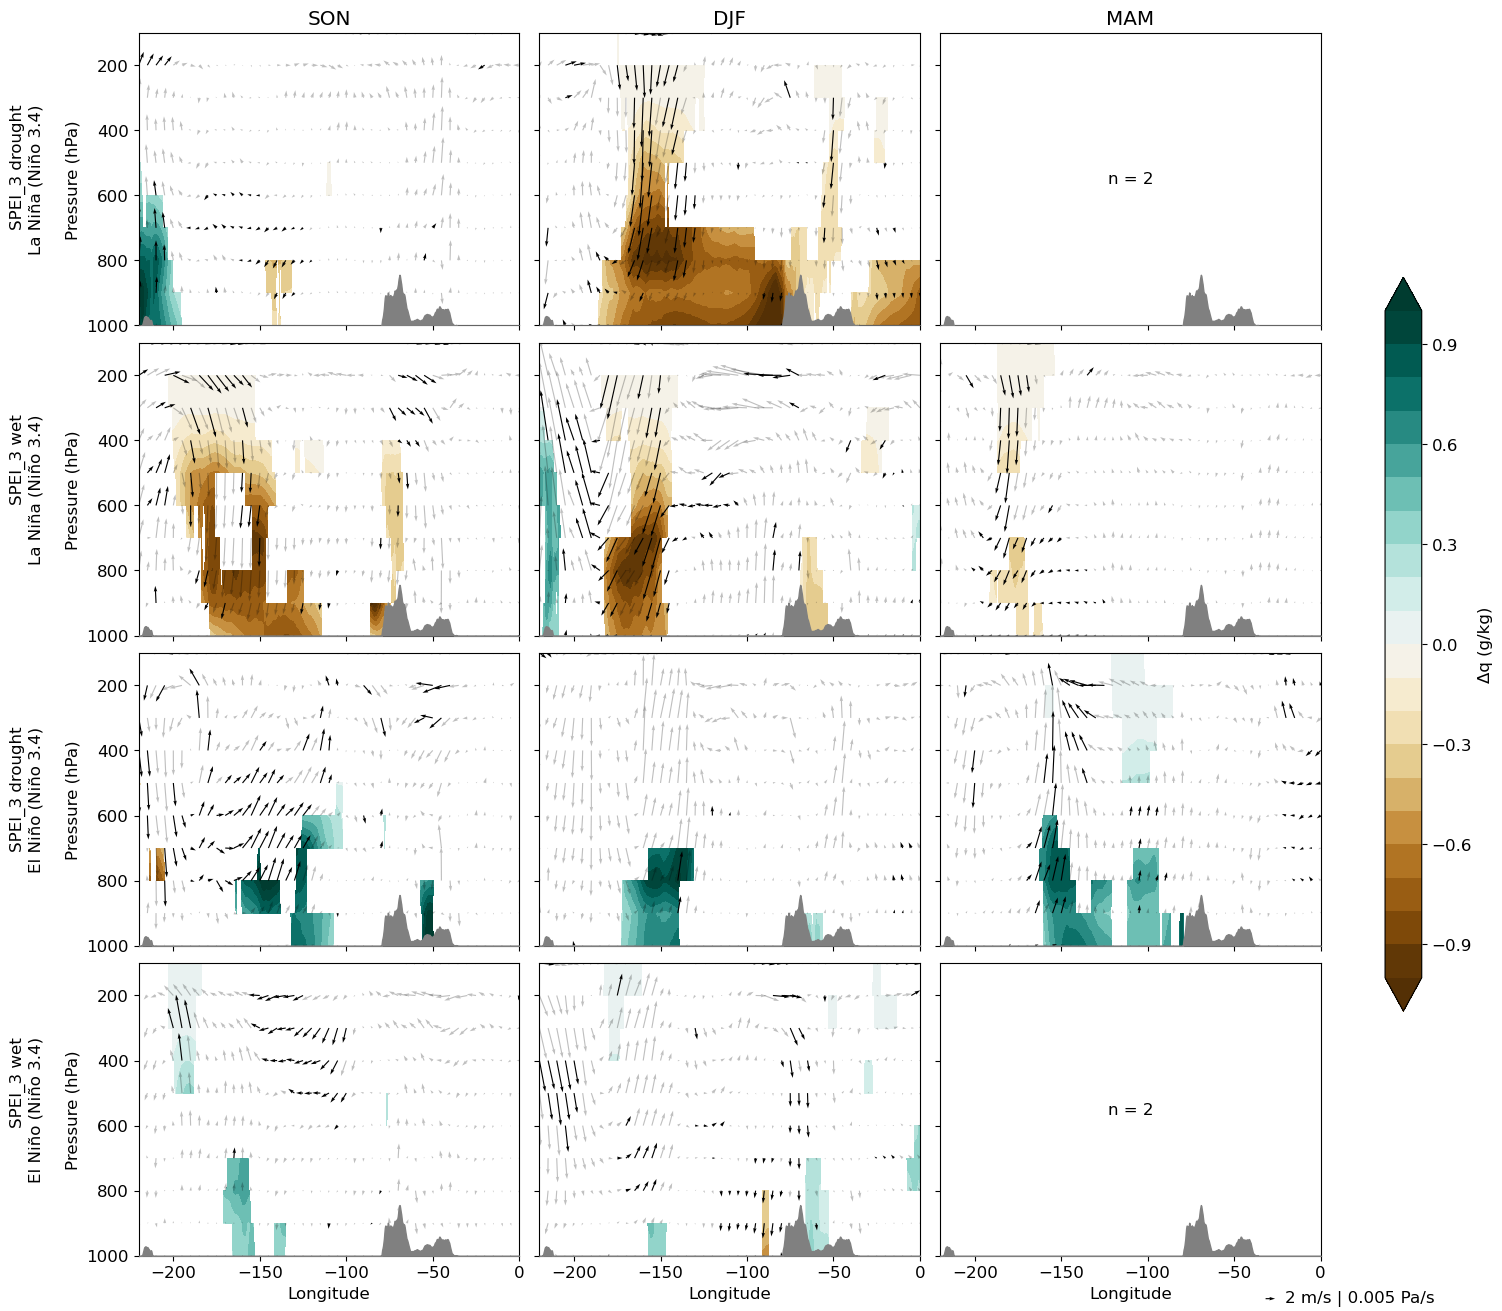

In [103]:
fig, axes = plot_xsection_drought_driver_vs_drought('nino34', drought_type, drought_threshold, wet_threshold, vhi_drought_threshold, vhi_wet_threshold)